In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

#archivo
nombre_archivo='TIAcianinas_datos_correctos.xlsx'

# Cargar el archivo Excel
datos = pd.read_excel(nombre_archivo)
print(datos.columns.tolist())

# La primera columna es la longitud de onda
onda_col = datos.columns[0]
# Las demás columnas son las muestras
muestras = datos.columns[1:]

['Wavelength_nm', 'DTTC', 'DTDC', 'DTCI']


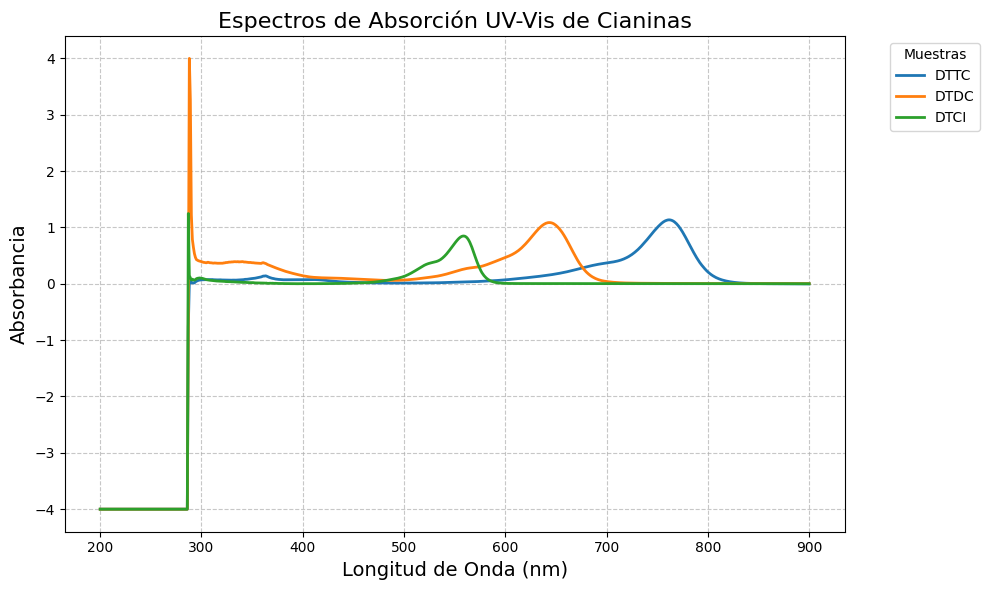

In [6]:
# BLOQUE 2: Gráfico de Espectros UV-Vis
plt.figure(figsize=(10, 6))

# Iterar sobre todas las columnas y graficarlas
for muestra in muestras:
    plt.plot(datos[onda_col], datos[muestra], label=muestra, linewidth=2)

# Formato del gráfico
plt.title('Espectros de Absorción UV-Vis de Cianinas', fontsize=16)
plt.xlabel('Longitud de Onda (nm)', fontsize=14)
plt.ylabel('Absorbancia', fontsize=14)
plt.legend(title='Muestras', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

# Mostrar el gráfico
plt.show()

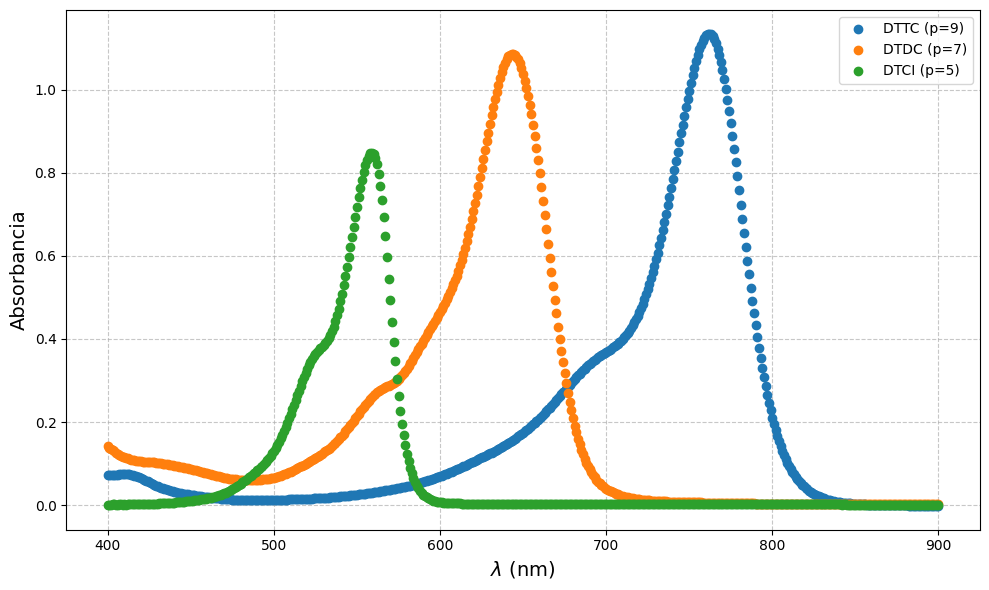

In [9]:
#Datos limpios (saco el ruido térmico de los 300nm)
datos_1 = datos[(datos['Wavelength_nm'] >= 400)]
onda_col = datos_1.columns[0] #la longitud de onda
muestras = ['DTTC', 'DTDC', 'DTCI']
muestras_1 = ['DTTC (p=9)', 'DTDC (p=7)', 'DTCI (p=5)']

plt.figure(figsize=(10, 6))

# Usamos zip para iterar sobre ambas listas en paralelo
for muestra, etiqueta in zip(muestras, muestras_1):
    plt.plot(
        datos_1['Wavelength_nm'],
        datos_1[muestra],
        'o',
        label=etiqueta, # Asignamos la etiqueta individual correcta
    )

plt.xlabel(r'$\lambda$ (nm)', fontsize=14) # Usamos r'' para que LaTeX se renderice bien
plt.ylabel('Absorbancia', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
#Búsqueda del pico máximo de absorción
lambdas_max = {}

print("Resultados experimentales (Picos máximos de absorción):")
print("-" * 50)
datos_1 = datos[(datos['Wavelength_nm'] >= 300)]
for muestra in muestras:
    # Encontrar el índice donde la absorbancia es máxima
    indice_max = datos_1[muestra].idxmax() #encuentra el maximo valor y nos da el lugar
    # Encontrar la longitud de onda en ese índice
    l_max = datos_1[onda_col].loc[indice_max]
    absorbancia_max = datos_1[muestra].loc[indice_max]

    # Guardar los datos extraídos para el gráfico final
    lambdas_max[muestra] = l_max
    print(f"{muestra}: Lambda_max = {l_max} nm (Absorbancia: {absorbancia_max:.3f})")



In [ ]:
# ==============================================================================
# Ajuste para encontrar la longitud de onda máxima mediante gaussianas (TIO)
# ==============================================================================

# Definimos una única función gaussiana
def gaussian_function(x, centro, sigma, amplitud):
    return amplitud * np.exp(-((x - centro) ** 2) / (2 * sigma ** 2))

# 1. PARA LAS DTTC
muestra_dttc = 'DTTC'

# RANGO y AMPLITUD
rango_min_dttc = 550
rango_max_dttc = 900
amplitud_dttc = datos_1[muestra_dttc].max()  # Toma la absorbancia máxima automáticamente

# 1. Filtramos los datos
filtro_dttc = (datos_1[onda_col] >= rango_min_dttc) & (datos_1[onda_col] <= rango_max_dttc)
x_dttc = datos_1[onda_col][filtro_dttc].values
y_dttc = datos_1[muestra_dttc][filtro_dttc].values

# 2. Hacemos el ajuste (centro estimado en ~762)
parametros_dttc, _ = curve_fit(lambda x, centro, sigma: gaussian_function(x, centro, sigma, amplitud_dttc), x_dttc, y_dttc, p0=[762, 20])
centro_dttc = parametros_dttc[0]
sigma_dttc = abs(parametros_dttc[1]) # abs() por si el algoritmo devuelve un sigma negativo

print(f"DTTC -> Longitud de onda máxima: {centro_dttc:.2f} nm | Sigma (Error): {sigma_dttc:.2f} nm")

# 3. Graficamos
plt.figure(figsize=(10, 6))
plt.plot(x_dttc, y_dttc, 'o', color='tab:blue', label='Datos Experimentales DTTC')
plt.plot(x_dttc, gaussian_function(x_dttc, centro_dttc, sigma_dttc, amplitud_dttc), 'r--', label='Ajuste Gaussiano', linewidth=2)
plt.title('Ajuste del Pico - DTTC', fontsize=16)
plt.xlabel('Longitud de Onda (nm)', fontsize=14)
plt.ylabel('Absorbancia', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


# ==============================================================================
# 2. PARA LAS DTDC
# ==============================================================================
muestra_dtdc = 'DTDC'

# PARAMETROS
rango_min_dtdc = 450
rango_max_dtdc = 750
amplitud_dtdc = datos_1[muestra_dtdc].max()

# 1. Filtramos los datos
filtro_dtdc = (datos_1[onda_col] >= rango_min_dtdc) & (datos_1[onda_col] <= rango_max_dtdc)
x_dtdc = datos_1[onda_col][filtro_dtdc].values
y_dtdc = datos_1[muestra_dtdc][filtro_dtdc].values

# 2. Hacemos el ajuste (centro estimado en ~643)
parametros_dtdc, _ = curve_fit(lambda x, centro, sigma: gaussian_function(x, centro, sigma, amplitud_dtdc), x_dtdc, y_dtdc, p0=[643, 20])
centro_dtdc = parametros_dtdc[0]
sigma_dtdc = abs(parametros_dtdc[1])

print(f"DTDC -> Longitud de onda máxima: {centro_dtdc:.2f} nm | Sigma (Error): {sigma_dtdc:.2f} nm")

# 3. Graficamos
plt.figure(figsize=(10, 6))
plt.plot(x_dtdc, y_dtdc, 'o', color='tab:orange', label='Datos Experimentales DTDC')
plt.plot(x_dtdc, gaussian_function(x_dtdc, centro_dtdc, sigma_dtdc, amplitud_dtdc), 'r--', label='Ajuste Gaussiano', linewidth=2)
plt.title('Ajuste del Pico - DTDC', fontsize=16)
plt.xlabel('Longitud de Onda (nm)', fontsize=14)
plt.ylabel('Absorbancia', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


# ==============================================================================
# 3. PARA LAS DTCI
# ==============================================================================
muestra_dtci = 'DTCI'

# PARAMETROS
rango_min_dtci = 450
rango_max_dtci = 650
amplitud_dtci = datos_1[muestra_dtci].max()

# 1. Filtramos los datos
filtro_dtci = (datos_1[onda_col] >= rango_min_dtci) & (datos_1[onda_col] <= rango_max_dtci)
x_dtci = datos_1[onda_col][filtro_dtci].values
y_dtci = datos_1[muestra_dtci][filtro_dtci].values

# 2. Hacemos el ajuste (centro estimado en ~559)
parametros_dtci, _ = curve_fit(lambda x, centro, sigma: gaussian_function(x, centro, sigma, amplitud_dtci), x_dtci, y_dtci, p0=[559, 20])
centro_dtci = parametros_dtci[0]
sigma_dtci = abs(parametros_dtci[1])

print(f"DTCI -> Longitud de onda máxima: {centro_dtci:.2f} nm | Sigma (Error): {sigma_dtci:.2f} nm")

# 3. Graficamos
plt.figure(figsize=(10, 6))
plt.plot(x_dtci, y_dtci, 'o', color='tab:green', label='Datos Experimentales DTCI')
plt.plot(x_dtci, gaussian_function(x_dtci, centro_dtci, sigma_dtci, amplitud_dtci), 'r--', label='Ajuste Gaussiano', linewidth=2)
plt.title('Ajuste del Pico - DTCI', fontsize=16)
plt.xlabel('Longitud de Onda (nm)', fontsize=14)
plt.ylabel('Absorbancia', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

(Ver arriba) Para el de las oxo-cianinas usamos el comanod iloc() pero eso te da la casilla, no el valor del la longitud de onda, entonces acá lo reemplacé por loc()

In [ ]:
#Comparación Modelo Teórico vs Resultados Experimentales

# 1. Definir la función del modelo teórico (Pozo de potencial)
def calcular_lambda_teorico(p):
    # Constantes físicas
    h = 6.626e-34      # Constante de Planck (J*s)
    m = 9.109e-31      # Masa del electrón (kg)
    c = 3.0e8          # Velocidad de la luz (m/s)
    d = 0.14e-9        # Distancia interatómica C-C (metros)

    # Ecuación del pozo de potencial unidimensional: lambda = [8 * m * c * ((p+2)*d)^2] / [h * (p+4)]
    numerador = 8 * m * c * ((p + 2) * d)**2
    denominador = h * (p + 4)
    lambda_metros = numerador / denominador

    # Convertir de metros a nanómetros (nm)
    return lambda_metros * 1e9

# 2. Generar datos teóricos para graficar una línea
p_teoricos = np.linspace(3, 11, 50)
lambda_teoricos = [calcular_lambda_teorico(p) for p in p_teoricos]

# 3. Graficar todo junto
plt.figure(figsize=(9, 6))

#modelo teórico
plt.plot(p_teoricos, lambda_teoricos, 'k--', label='Modelo Teórico', linewidth=2)
p_exp = np.array([5,7,9])
lambda_exp = np.array([559,643,762])
sigma_exp = np.array([17,28,28])

#datos experimentales (FALTA AGREGAR ERROR)
plt.errorbar(x=9, y=762, yerr=22, fmt='o', color='tab:blue', label="DOTC (p=9)", capsize=5, markersize=7)
plt.errorbar(x=7, y=643, yerr=17, fmt='o', color='tab:orange', label="DODCI (p=7)", capsize=5, markersize=7)
plt.errorbar(x=5, y=551, yerr=17, fmt='o', color='tab:green', label="DOCI (p=5)", capsize=5, markersize=7)

plt.xlim(3, 10)
plt.ylim(200, 900)
plt.title('Comparación pozo de potencial infinito vs Datos TIA-Cianinas')
plt.xlabel("Número de carbonos en la cadena (p)")
plt.ylabel('Longitud de onda máxima [nm]')
plt.show()

# ==============================================================================
# PARTE 2: Ajuste del Modelo Modificando la Longitud Efectiva L = (p + alfa)*d
# ==============================================================================
# 1. Definir la nueva función para el ajuste (alfa es el parámetro libre)
def funcion_ajuste_alfa(p, alfa):
    # Constantes físicas
    h = 6.626e-34
    m = 9.109e-31
    c = 3.0e8
    d = 0.14e-9 # La distancia d se mantiene fija[cite: 1]

    # Nueva ecuación donde la longitud efectiva es L = (p + alfa) * d
    numerador = 8 * m * c * ((p + alfa) * d)**2
    denominador = h * (p + 4)
    lambda_metros = numerador / denominador

    return lambda_metros * 1e9

# 2. Realizar el ajuste (pasamos sigma_exp para que el ajuste considere los errores)
# Damos un valor inicial aproximado de p0=[3.0] para ayudar al algoritmo
parametros_optimos, covarianza = curve_fit(funcion_ajuste_alfa, p_exp, lambda_exp, p0=[3.0], sigma=sigma_exp, absolute_sigma=True)
alfa_optimo = parametros_optimos[0]
# Calcular el error estándar (incertidumbre) tomando la raíz cuadrada de la diagonal de la covarianza
error_alfa = np.sqrt(covarianza[0, 0])

print(f"El parámetro alfa óptimo para TIO es: {alfa_optimo:.3f} ± {error_alfa:.3f}")

# 3. Generar datos teóricos para la nueva curva ajustada
lambda_ajustados = funcion_ajuste_alfa(p_teoricos, alfa_optimo)

# 4. Graficar
plt.figure(figsize=(9, 6))

# Modelos
plt.plot(p_teoricos, lambda_teoricos, 'k--', label='Modelo Teórico Original ($\\alpha=2$)', linewidth=2)
plt.plot(p_teoricos, lambda_ajustados, 'g-', label=f'Modelo Ajustado ($\\alpha = {alfa_optimo:.2f}$)', linewidth=2)

# Puntos experimentales con barras de error
plt.errorbar(x=9, y=762, yerr=28, fmt='o', color='tab:blue', label="DTTC (p=9)", capsize=5, markersize=7)
plt.errorbar(x=7, y=643, yerr=28, fmt='o', color='tab:orange', label="DTDC (p=7)", capsize=5, markersize=7)
plt.errorbar(x=5, y=559, yerr=17, fmt='o', color='tab:green', label="DTCI (p=5)", capsize=5, markersize=7)

# Formato del gráfico
plt.title('Comparación: Modelo Teórico vs Modelo Ajustado vs Datos', fontsize=14)
plt.xlabel('Número de carbonos en la cadena (p)', fontsize=12)
plt.ylabel('Longitud de onda de máxima absorción $\lambda_{max}$ (nm)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(np.arange(3, 12, 2))

plt.tight_layout()
plt.show()

